<a href="https://colab.research.google.com/github/prantiqueroy/dhaka-air-enforcement/blob/main/notebooks/02_pm25_download.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import requests
import time
from google.colab import userdata

API_KEY = userdata.get("OPENAQ_API_KEY")
HEADERS = {"X-API-Key": API_KEY}
BASE = "https://api.openaq.org/v3"
print("Key loaded:", API_KEY is not None)

Key loaded: True


In [2]:
r = requests.get(f"{BASE}/locations",
                 headers=HEADERS,
                 params={"coordinates": "23.80,90.42", "radius": 10000, "limit": 100})
for loc in r.json()["results"]:
    for s in loc["sensors"]:
        if s["parameter"]["name"] == "pm25":
            print(loc["id"], "|", loc["name"], "| sensor id:", s["id"])

22 | SPARTAN - Dhaka University | sensor id: 41
2445 | US Diplomatic Post: Dhaka | sensor id: 4680
8415 | Dhaka | sensor id: 24434
1285342 | SPARTAN - Dhaka University | sensor id: 6566258
5105944 | smart air bangladesh office | sensor id: 13623705
6157905 | RAJUK Uttara Apartment Project, Sector - 18, Uttara | sensor id: 14839069
6219691 | Abdullahbag, North Badda | sensor id: 15296733
6234363 | Gulshan Society Lake Park | Dhaka | Smart Air Bangladesh | sensor id: 15403598
6236590 | Hazaribagh, Jigatola | Dhaka | Smart Air Bangladesh | sensor id: 15420149
6240023 | Dhanmondi, Road No. 7 | Dhaka l Smart Air Bangladesh | sensor id: 15445821
6240773 | Kalshi, Mirpur-12 | Dhaka l Smart Air Bangladesh | sensor id: 15451666
6242079 | Moghbazar; Bhodro Goli | Dhaka | Smart Air Bangladesh | sensor id: 15461146
6242232 | Baridhara, Park Road | Dhaka l Smart Air Bangladesh | sensor id: 15462183
6251395 | Mirpur, Shewrapara | Dhaka | Smart Air Bangladesh | sensor id: 15530269
6271076 | Baridhara

In [3]:
# Look for the monitor whose name mentions the US embassy / diplomatic post
sensor_id = None
for loc in r.json()["results"]:
    name = loc["name"].lower()
    if "us" in name.split() or "diplomatic" in name or "embassy" in name or "consulate" in name:
        for s in loc["sensors"]:
            if s["parameter"]["name"] == "pm25":
                sensor_id = s["id"]
                print("Picked:", loc["name"], "| sensor id:", sensor_id)

if sensor_id is None:
    print("Not found automatically. Send Claude a screenshot of Cell 2's output.")

Picked: US Diplomatic Post: Dhaka | sensor id: 4680


In [4]:
rows = []
for year in range(2016, 2026):
    page = 1
    while True:
        resp = requests.get(
            f"{BASE}/sensors/{sensor_id}/hours",
            headers=HEADERS,
            params={"datetime_from": f"{year}-01-01", "datetime_to": f"{year+1}-01-01",
                    "limit": 1000, "page": page})
        results = resp.json().get("results", [])
        for item in results:
            rows.append({"time": item["period"]["datetimeFrom"]["local"],
                         "pm25": item["value"]})
        if len(results) < 1000:
            break
        page += 1
        time.sleep(1)          # pause so we don't overload the server
    print(year, "done. Total hours so far:", len(rows))

2016 done. Total hours so far: 5656
2017 done. Total hours so far: 5656
2018 done. Total hours so far: 5656
2019 done. Total hours so far: 5656
2020 done. Total hours so far: 5656
2021 done. Total hours so far: 5656
2022 done. Total hours so far: 5656
2023 done. Total hours so far: 5656
2024 done. Total hours so far: 5656
2025 done. Total hours so far: 5656


In [5]:
pm = pd.DataFrame(rows)
pm["time"] = pd.to_datetime(pm["time"].str[:19])   # Dhaka local time
pm = pm.sort_values("time").reset_index(drop=True)
print("First reading:", pm["time"].min())
print("Last reading: ", pm["time"].max())
print("Total hours:  ", len(pm))
pm.to_csv("dhaka_pm25_2016_2025.csv", index=False)
pm.head()

First reading: 2016-03-11 03:00:00
Last reading:  2016-11-09 21:00:00
Total hours:   5656


,time,pm25
0,2016-03-11 03:00:00,71.0
1,2016-03-11 04:00:00,76.0
2,2016-03-11 05:00:00,76.0
3,2016-03-11 06:00:00,94.0
4,2016-03-11 07:00:00,116.0


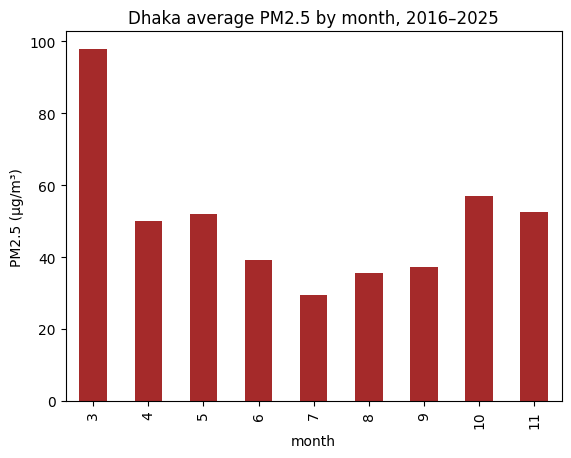

In [6]:
import matplotlib.pyplot as plt
pm["month"] = pm["time"].dt.month
pm.groupby("month")["pm25"].mean().plot(kind="bar", color="brown")
plt.title("Dhaka average PM2.5 by month, 2016–2025")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

In [7]:
print("Sensor used:", sensor_id)
print("First reading:", pm["time"].min())
print("Last reading: ", pm["time"].max())
print("Total hours:  ", len(pm))
print(pm["time"].dt.year.value_counts().sort_index())
print("Last server reply:", resp.status_code, resp.text[:300])

Sensor used: 4680
First reading: 2016-03-11 03:00:00
Last reading:  2016-11-09 21:00:00
Total hours:   5656
time
2016    5656
Name: count, dtype: int64
Last server reply: 200 {"meta":{"name":"openaq-api","website":"/","page":1,"limit":1000,"found":0},"results":[]}


In [8]:
r = requests.get(f"{BASE}/locations",
                 headers=HEADERS,
                 params={"coordinates": "23.80,90.42", "radius": 10000, "limit": 100})
for loc in r.json()["results"]:
    first = (loc.get("datetimeFirst") or {}).get("local", "?")[:10]
    last  = (loc.get("datetimeLast")  or {}).get("local", "?")[:10]
    for s in loc["sensors"]:
        if s["parameter"]["name"] == "pm25":
            print(f"sensor {s['id']:>8} | {first} to {last} | {loc['name']} | provider: {(loc.get('provider') or {}).get('name')}")

sensor       41 | ? to ? | SPARTAN - Dhaka University | provider: Spartan
sensor     4680 | 2016-03-11 to 2016-11-09 | US Diplomatic Post: Dhaka | provider: StateAir Dhaka
sensor    24434 | 2016-11-10 to 2025-03-24 | Dhaka | provider: AirNow
sensor  6566258 | ? to ? | SPARTAN - Dhaka University | provider: SPARTAN Network
sensor 13623705 | 2025-07-17 to 2025-10-22 | smart air bangladesh office | provider: AirGradient
sensor 14839069 | 2025-12-09 to 2026-10-13 | RAJUK Uttara Apartment Project, Sector - 18, Uttara | provider: AirGradient
sensor 15296733 | 2026-01-29 to 2026-01-29 | Abdullahbag, North Badda | provider: AirGradient
sensor 15403598 | 2026-02-09 to 2026-10-13 | Gulshan Society Lake Park | Dhaka | Smart Air Bangladesh | provider: AirGradient
sensor 15420149 | 2026-02-11 to 2026-10-13 | Hazaribagh, Jigatola | Dhaka | Smart Air Bangladesh | provider: AirGradient
sensor 15445821 | 2026-02-14 to 2026-10-10 | Dhanmondi, Road No. 7 | Dhaka l Smart Air Bangladesh | provider: AirGrad

In [9]:
def download_sensor(sid, start_year, end_year):
    out = []
    for year in range(start_year, end_year + 1):
        page = 1
        while True:
            resp = requests.get(
                f"{BASE}/sensors/{sid}/hours", headers=HEADERS,
                params={"datetime_from": f"{year}-01-01", "datetime_to": f"{year+1}-01-01",
                        "limit": 1000, "page": page})
            results = resp.json().get("results", [])
            for item in results:
                out.append({"time": item["period"]["datetimeFrom"]["local"],
                            "pm25": item["value"], "sensor": sid})
            if len(results) < 1000:
                break
            page += 1
            time.sleep(1)
        print(f"sensor {sid}, {year}: total so far {len(out)}")
    return out

rows = download_sensor(4680, 2016, 2016) + download_sensor(24434, 2016, 2025)

pm = pd.DataFrame(rows)
pm["time"] = pd.to_datetime(pm["time"].str[:19])
pm = pm.drop_duplicates(subset="time").sort_values("time").reset_index(drop=True)

print("First reading:", pm["time"].min())
print("Last reading: ", pm["time"].max())
print("Total hours:  ", len(pm))
print(pm["time"].dt.year.value_counts().sort_index())
pm.to_csv("dhaka_pm25_2016_2025.csv", index=False)

sensor 4680, 2016: total so far 5656
sensor 24434, 2016: total so far 1201
sensor 24434, 2017: total so far 8218
sensor 24434, 2018: total so far 14218
sensor 24434, 2019: total so far 20218
sensor 24434, 2020: total so far 27218
sensor 24434, 2021: total so far 34218
sensor 24434, 2022: total so far 41218
sensor 24434, 2023: total so far 47218
sensor 24434, 2024: total so far 54218
sensor 24434, 2025: total so far 56205
First reading: 2016-03-11 03:00:00
Last reading:  2025-03-24 18:00:00
Total hours:   61861
time
2016    6857
2017    7017
2018    6000
2019    6000
2020    7000
2021    7000
2022    7000
2023    6000
2024    7000
2025    1987
Name: count, dtype: int64


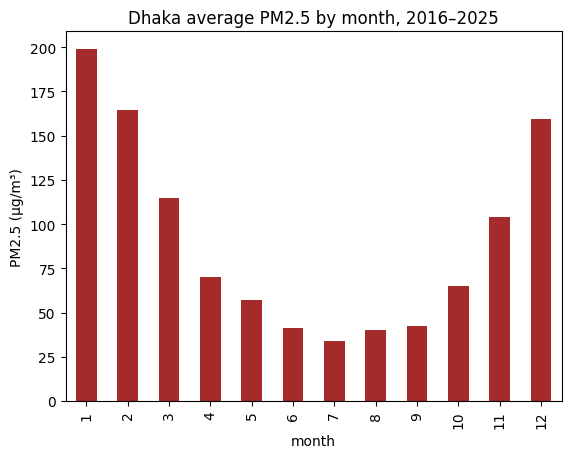

In [10]:
pm["month"] = pm["time"].dt.month
pm.groupby("month")["pm25"].mean().plot(kind="bar", color="brown")
plt.title("Dhaka average PM2.5 by month, 2016–2025")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

In [11]:
def get_month(sid, start, end):
    for attempt in range(6):
        resp = requests.get(f"{BASE}/sensors/{sid}/hours", headers=HEADERS,
                            params={"datetime_from": start, "datetime_to": end, "limit": 1000})
        if resp.status_code == 200:
            return resp.json().get("results", [])
        print(f"  server said {resp.status_code}, waiting and retrying...")
        time.sleep(15)
    print(f"  FAILED: {sid} {start}")
    return []

rows = []
for sid, first, last in [(4680, "2016-03-01", "2016-11-30"), (24434, "2016-11-01", "2025-03-31")]:
    for m in pd.date_range(first, last, freq="MS"):
        start, end = m.strftime("%Y-%m-%d"), (m + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
        for item in get_month(sid, start, end):
            rows.append({"time": item["period"]["datetimeFrom"]["local"],
                         "pm25": item["value"], "sensor": sid})
        time.sleep(1.5)
    print(f"sensor {sid} finished, total rows {len(rows)}")

pm = pd.DataFrame(rows)
pm["time"] = pd.to_datetime(pm["time"].str[:19])
pm = pm.drop_duplicates(subset="time").sort_values("time").reset_index(drop=True)
print("First:", pm["time"].min(), "| Last:", pm["time"].max(), "| Total hours:", len(pm))
print(pm["time"].dt.year.value_counts().sort_index())
pm.to_csv("dhaka_pm25_2016_2025.csv", index=False)

sensor 4680 finished, total rows 5656
sensor 24434 finished, total rows 72035
First: 2016-03-11 03:00:00 | Last: 2025-03-24 18:00:00 | Total hours: 72035
time
2016    6857
2017    7017
2018    7025
2019    8283
2020    8188
2021    7983
2022    8441
2023    7493
2024    8761
2025    1987
Name: count, dtype: int64
